# Task 1 — Anti-Cheat EDA
Verify → Clean → Explore

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline.random_seed import set_seed
SEED = set_seed()

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid")
RAW = ROOT / "src" / "task1" / "data" / "raw"
TARGET = "is_cheater"
ID = "player_id"

# Verify

In [2]:
train_raw = pd.read_csv(RAW / "train.csv")
test_raw = pd.read_csv(RAW / "test.csv")

assert TARGET in train_raw and TARGET not in test_raw
assert set(train_raw.columns) - {TARGET} == set(test_raw.columns)
assert train_raw[ID].notna().all() and test_raw[ID].notna().all()
assert train_raw[ID].is_unique and test_raw[ID].is_unique
assert not set(train_raw[ID]).intersection(test_raw[ID])
assert set(train_raw[TARGET].dropna().unique()) <= {0, 1}

feature_cols = [c for c in test_raw.columns if c != ID]
assert len(feature_cols) == 31
assert all(pd.api.types.is_numeric_dtype(train_raw[c]) and pd.api.types.is_numeric_dtype(test_raw[c]) for c in feature_cols)

pd.DataFrame({
    "rows": [len(train_raw), len(test_raw)],
    "columns": [train_raw.shape[1], test_raw.shape[1]],
    "duplicate_rows": [train_raw.duplicated().sum(), test_raw.duplicated().sum()],
    "duplicate_ids": [train_raw[ID].duplicated().sum(), test_raw[ID].duplicated().sum()],
    "missing_cells": [train_raw.isna().sum().sum(), test_raw.isna().sum().sum()],
}, index=["train", "test"])

,rows,columns,duplicate_rows,duplicate_ids,missing_cells
train,104000,33,0,0,399347
test,25889,32,0,0,64190


In [3]:
display(train_raw.head())
display(test_raw.head())
display(pd.DataFrame({"train_dtype": train_raw.dtypes.astype(str), "test_dtype": test_raw.dtypes.astype(str)}))

,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,...,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.176237,54.245482,85.662938,25.457845,0.774864,83.828120,261.721035,34.009104,0.022950,...,0.692063,0.834387,0.550694,0.491093,0.483104,73.476007,55.711383,0.790575,0.893005,0.0
1,P044854,6.510362,54.388554,99.174621,36.679574,0.813276,148.295650,1075.704820,72.863639,0.067318,...,0.616427,0.853019,0.556390,0.562038,NaN,NaN,NaN,0.793743,0.956779,0.0
2,P036798,5.457167,60.417905,100.000000,44.558707,0.720939,117.662956,1031.540114,99.075389,0.055238,...,NaN,0.362643,0.579663,0.129658,0.335847,40.784374,NaN,0.563563,0.868322,0.0
3,P079617,NaN,35.180729,67.756853,42.750853,0.379890,348.463623,525.534446,39.694695,0.028952,...,0.501457,0.398195,0.630693,0.512969,0.178991,60.185066,135.341158,NaN,0.938778,NaN
4,P093830,3.747774,31.777986,80.689833,26.820793,0.567326,351.819822,296.179584,72.817519,0.040610,...,0.548742,0.485381,0.578093,0.421014,0.154923,59.359891,127.075580,0.471941,0.837420,NaN


,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,...,communication_rate,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement
0,P122189,4.590483,25.179182,78.625105,43.897113,0.792432,136.523187,820.741554,86.356161,0.086619,...,0.252098,0.736881,0.805226,0.784847,0.248891,0.364889,41.076808,127.086794,NaN,0.883818
1,P000044,6.808975,36.765169,46.945526,21.248344,0.518639,159.528899,494.827592,39.652498,0.056336,...,NaN,0.843940,0.846231,0.469260,0.149891,0.447656,93.021443,NaN,NaN,0.929157
2,P050138,7.011188,67.813425,76.673003,32.152543,0.616660,164.350410,950.516991,70.572353,0.066929,...,NaN,0.793235,0.750245,0.466052,0.121834,0.253373,33.938181,103.930616,0.642738,0.833456
3,P023303,6.963771,NaN,73.001855,42.889789,0.729165,134.469811,411.634798,42.941703,0.033085,...,0.374213,0.736164,0.573294,0.684945,0.272873,0.270324,68.659377,90.100377,0.560450,0.871779
4,P128406,7.333965,35.040094,100.000000,58.089728,0.612333,96.739793,392.877976,33.445138,0.026325,...,0.476452,0.435416,0.823661,0.778576,0.470726,0.353087,NaN,48.861860,0.723609,0.870531


,train_dtype,test_dtype
account_age_days,float64,float64
accuracy_score,float64,float64
aiming_smoothness,float64,float64
avg_session_length_min,float64,float64
buy_decision_score,float64,float64
clutch_success_rate,float64,float64
communication_rate,float64,float64
crosshair_placement,float64,float64
damage_per_round,float64,float64
device_changes_count,float64,float64


In [4]:
label_counts = train_raw[TARGET].value_counts(dropna=False).rename(index={0.0: "Legitimate (0)", 1.0: "Cheater (1)"})
display(label_counts.to_frame("rows").assign(percent=lambda x: (100 * x.rows / len(train_raw)).round(2)))

missing = pd.DataFrame({
    "train_count": train_raw.isna().sum(),
    "train_pct": train_raw.isna().mean().mul(100),
    "test_count": test_raw.isna().sum(),
    "test_pct": test_raw.isna().mean().mul(100),
}).round(2)
display(missing.sort_values("train_pct", ascending=False))

,rows,percent
is_cheater,,
Legitimate (0),59091,56.82
Cheater (1),31725,30.50
NaN,13184,12.68


,train_count,train_pct,test_count,test_pct
survival_time_avg,25305,24.33,3380.0,13.06
weapon_switch_speed,25213,24.24,4009.0,15.49
avg_session_length_min,23895,22.98,408.0,1.58
movement_pattern_score,23324,22.43,2258.0,8.72
friend_network_size,23265,22.37,1227.0,4.74
reports_received,23193,22.30,3866.0,14.93
aiming_smoothness,21710,20.88,534.0,2.06
communication_rate,21402,20.58,2859.0,11.04
team_play_score,20235,19.46,2104.0,8.13
spray_control_score,17428,16.76,1442.0,5.57


In [5]:
numeric_train = train_raw[feature_cols].to_numpy()
numeric_test = test_raw[feature_cols].to_numpy()
print("Infinite values — train:", np.isinf(numeric_train).sum(), "test:", np.isinf(numeric_test).sum())
print("Fully empty feature rows — train:", train_raw[feature_cols].isna().all(axis=1).sum(),
      "test:", test_raw[feature_cols].isna().all(axis=1).sum())

display(train_raw[feature_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))

Infinite values — train: 0 test: 0
Fully empty feature rows — train: 0 test: 0


,count,mean,std,min,1%,25%,50%,75%,99%,max
kill_death_ratio,93962.0,4.738,1.517,0.500,1.882,3.712,4.567,5.536,9.501,12.000
headshot_percentage,101187.0,47.861,13.753,5.000,18.985,38.271,47.128,56.654,84.224,95.000
win_rate,98817.0,71.361,13.995,16.385,39.575,61.672,71.137,80.996,100.000,100.000
accuracy_score,103356.0,40.188,12.119,8.000,14.344,31.707,39.675,48.111,70.488,85.000
kill_consistency,94269.0,0.649,0.150,0.250,0.301,0.544,0.653,0.756,0.980,0.980
reaction_time_ms,95881.0,135.173,51.095,55.000,55.000,99.554,128.431,162.476,294.091,714.446
account_age_days,88983.0,495.254,350.935,1.005,8.375,156.222,479.877,762.091,1361.212,1499.650
level,96586.0,62.866,20.743,25.006,27.048,44.905,62.862,80.773,98.951,99.999
level_progression_speed,95560.0,0.365,1.595,0.003,0.009,0.041,0.081,0.214,4.659,80.029
friend_network_size,80735.0,137.767,84.605,0.000,3.000,64.000,135.000,206.000,330.000,349.000


In [6]:
range_rules = {
    "headshot_percentage": (0, 100), "win_rate": (0, 100),
    "night_play_ratio": (0, 1), "clutch_success_rate": (0, 1),
    "first_blood_rate": (0, 1), "utility_usage_rate": (0, 1),
}
range_check = []
for column, (low, high) in range_rules.items():
    range_check.append({
        "feature": column, "expected_range": f"[{low}, {high}]",
        "train_outside": train_raw[column].lt(low).sum() + train_raw[column].gt(high).sum(),
        "test_outside": test_raw[column].lt(low).sum() + test_raw[column].gt(high).sum(),
    })
display(pd.DataFrame(range_check))

,feature,expected_range,train_outside,test_outside
0,headshot_percentage,"[0, 100]",0,0
1,win_rate,"[0, 100]",0,0
2,night_play_ratio,"[0, 1]",0,0
3,clutch_success_rate,"[0, 1]",0,0
4,first_blood_rate,"[0, 1]",0,0
5,utility_usage_rate,"[0, 1]",0,0


# Clean

In [7]:
# Rows without a known target cannot enter supervised training or validation.
train_clean = train_raw.loc[train_raw[TARGET].notna()].copy()
test_clean = test_raw.copy()
train_clean[TARGET] = train_clean[TARGET].astype("int8")

assert not train_clean[TARGET].isna().any()
assert train_clean[ID].is_unique and test_clean[ID].is_unique
assert train_clean[feature_cols].equals(train_raw.loc[train_raw[TARGET].notna(), feature_cols])
assert test_clean.equals(test_raw)

pd.DataFrame({
    "rows": [len(train_raw), len(train_clean), len(test_clean)],
    "missing_target": [train_raw[TARGET].isna().sum(), train_clean[TARGET].isna().sum(), np.nan],
    "missing_features": [train_raw[feature_cols].isna().sum().sum(),
                         train_clean[feature_cols].isna().sum().sum(),
                         test_clean[feature_cols].isna().sum().sum()],
}, index=["raw train", "labeled train", "test"])

,rows,missing_target,missing_features
raw train,104000,13184.0,386163
labeled train,90816,0.0,336958
test,25889,NaN,64190


# Explore

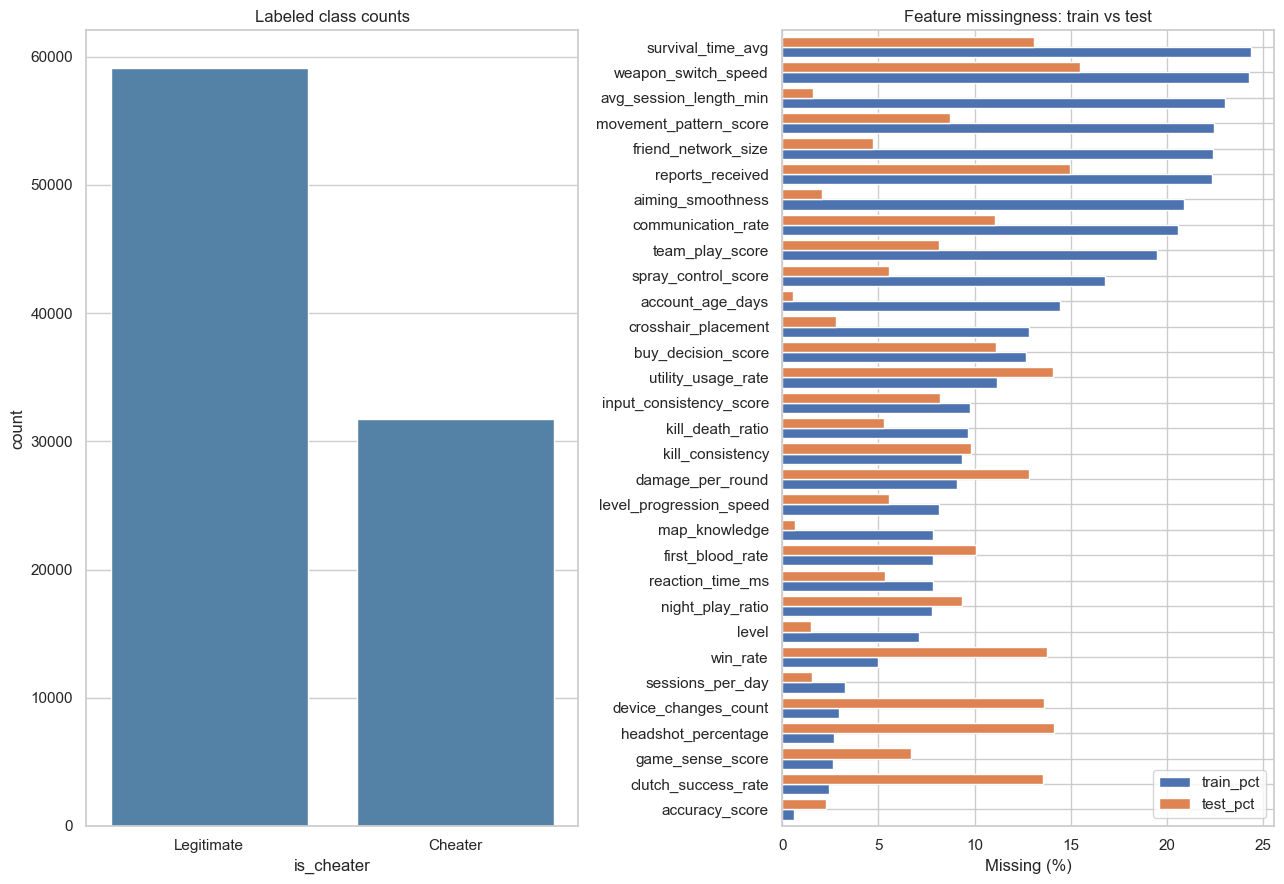

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train_clean, x=TARGET, order=[0, 1], ax=axes[0], color="steelblue")
axes[0].set_xticks([0, 1], labels=["Legitimate", "Cheater"])
axes[0].set_title("Labeled class counts")
missing_plot = missing.loc[feature_cols, ["train_pct", "test_pct"]].sort_values("train_pct")
missing_plot.plot.barh(ax=axes[1], figsize=(13, 9), width=.8)
axes[1].set_xlabel("Missing (%)")
axes[1].set_title("Feature missingness: train vs test")
plt.tight_layout()
plt.show()

In [9]:
by_class = train_clean.groupby(TARGET)[feature_cols].median().T
by_class.columns = ["legitimate_median", "cheater_median"]
by_class["difference"] = by_class["cheater_median"] - by_class["legitimate_median"]
display(by_class.round(3))

missing_by_class = train_clean.groupby(TARGET)[feature_cols].apply(lambda x: x.isna().mean().mul(100)).T
missing_by_class.columns = ["legitimate_missing_pct", "cheater_missing_pct"]
display(missing_by_class.round(2))

,legitimate_median,cheater_median,difference
kill_death_ratio,4.710,4.313,-0.396
headshot_percentage,48.459,44.775,-3.683
win_rate,71.876,69.712,-2.164
accuracy_score,40.449,38.256,-2.193
kill_consistency,0.657,0.643,-0.015
reaction_time_ms,127.267,130.585,3.318
account_age_days,510.232,425.567,-84.665
level,64.216,60.515,-3.701
level_progression_speed,0.079,0.086,0.007
friend_network_size,143.000,119.000,-24.000


,legitimate_missing_pct,cheater_missing_pct
kill_death_ratio,9.65,9.53
headshot_percentage,2.75,2.73
win_rate,4.89,5.05
accuracy_score,0.61,0.61
kill_consistency,9.41,9.33
reaction_time_ms,7.90,7.80
account_age_days,14.52,14.37
level,7.18,7.17
level_progression_speed,8.20,7.98
friend_network_size,22.34,22.19


,pearson_r
reports_received,-0.337
crosshair_placement,-0.228
kill_death_ratio,-0.134
headshot_percentage,-0.133
game_sense_score,-0.125
account_age_days,-0.098
accuracy_score,-0.089
level,-0.082
spray_control_score,-0.077
friend_network_size,-0.071


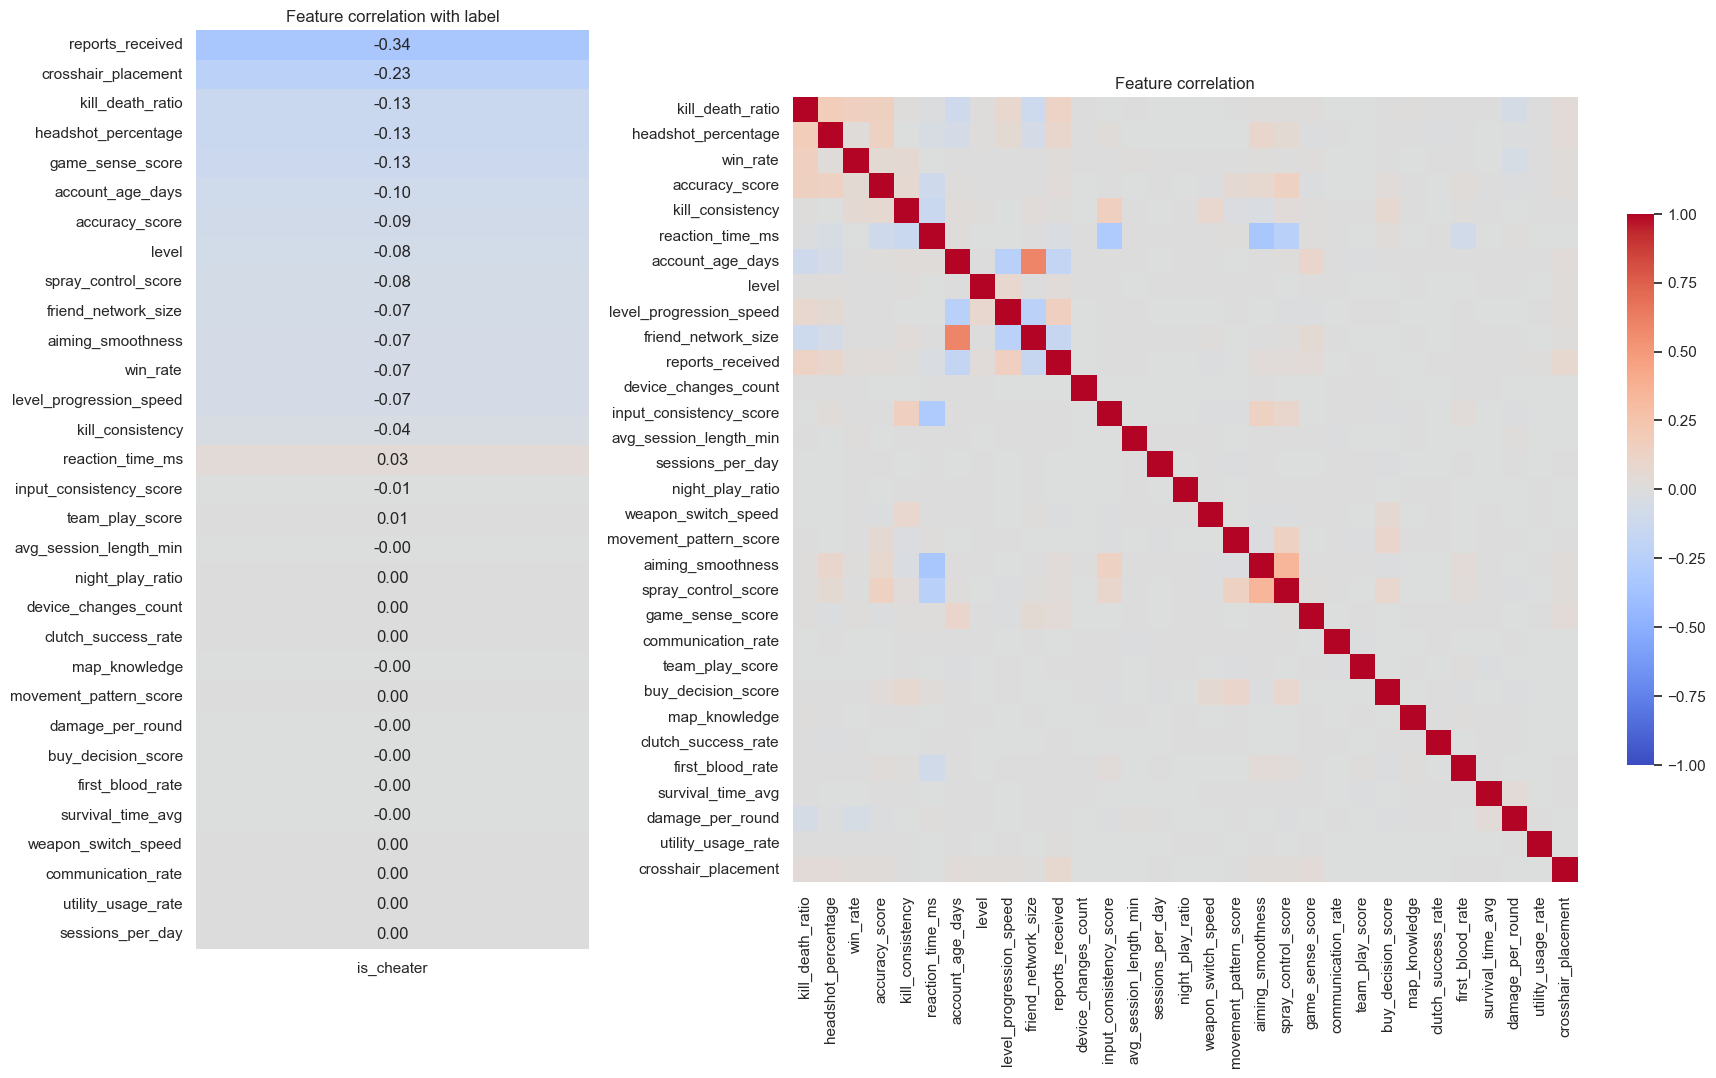

In [10]:
correlations = train_clean[feature_cols + [TARGET]].corr()
target_corr = correlations[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(target_corr.rename("pearson_r").to_frame().round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 11), gridspec_kw={"width_ratios": [1, 2.5]})
sns.heatmap(target_corr.to_frame(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Feature correlation with label")
sns.heatmap(correlations.loc[feature_cols, feature_cols], cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[1], square=True, cbar_kws={"shrink": .6})
axes[1].set_title("Feature correlation")
plt.tight_layout()
plt.show()

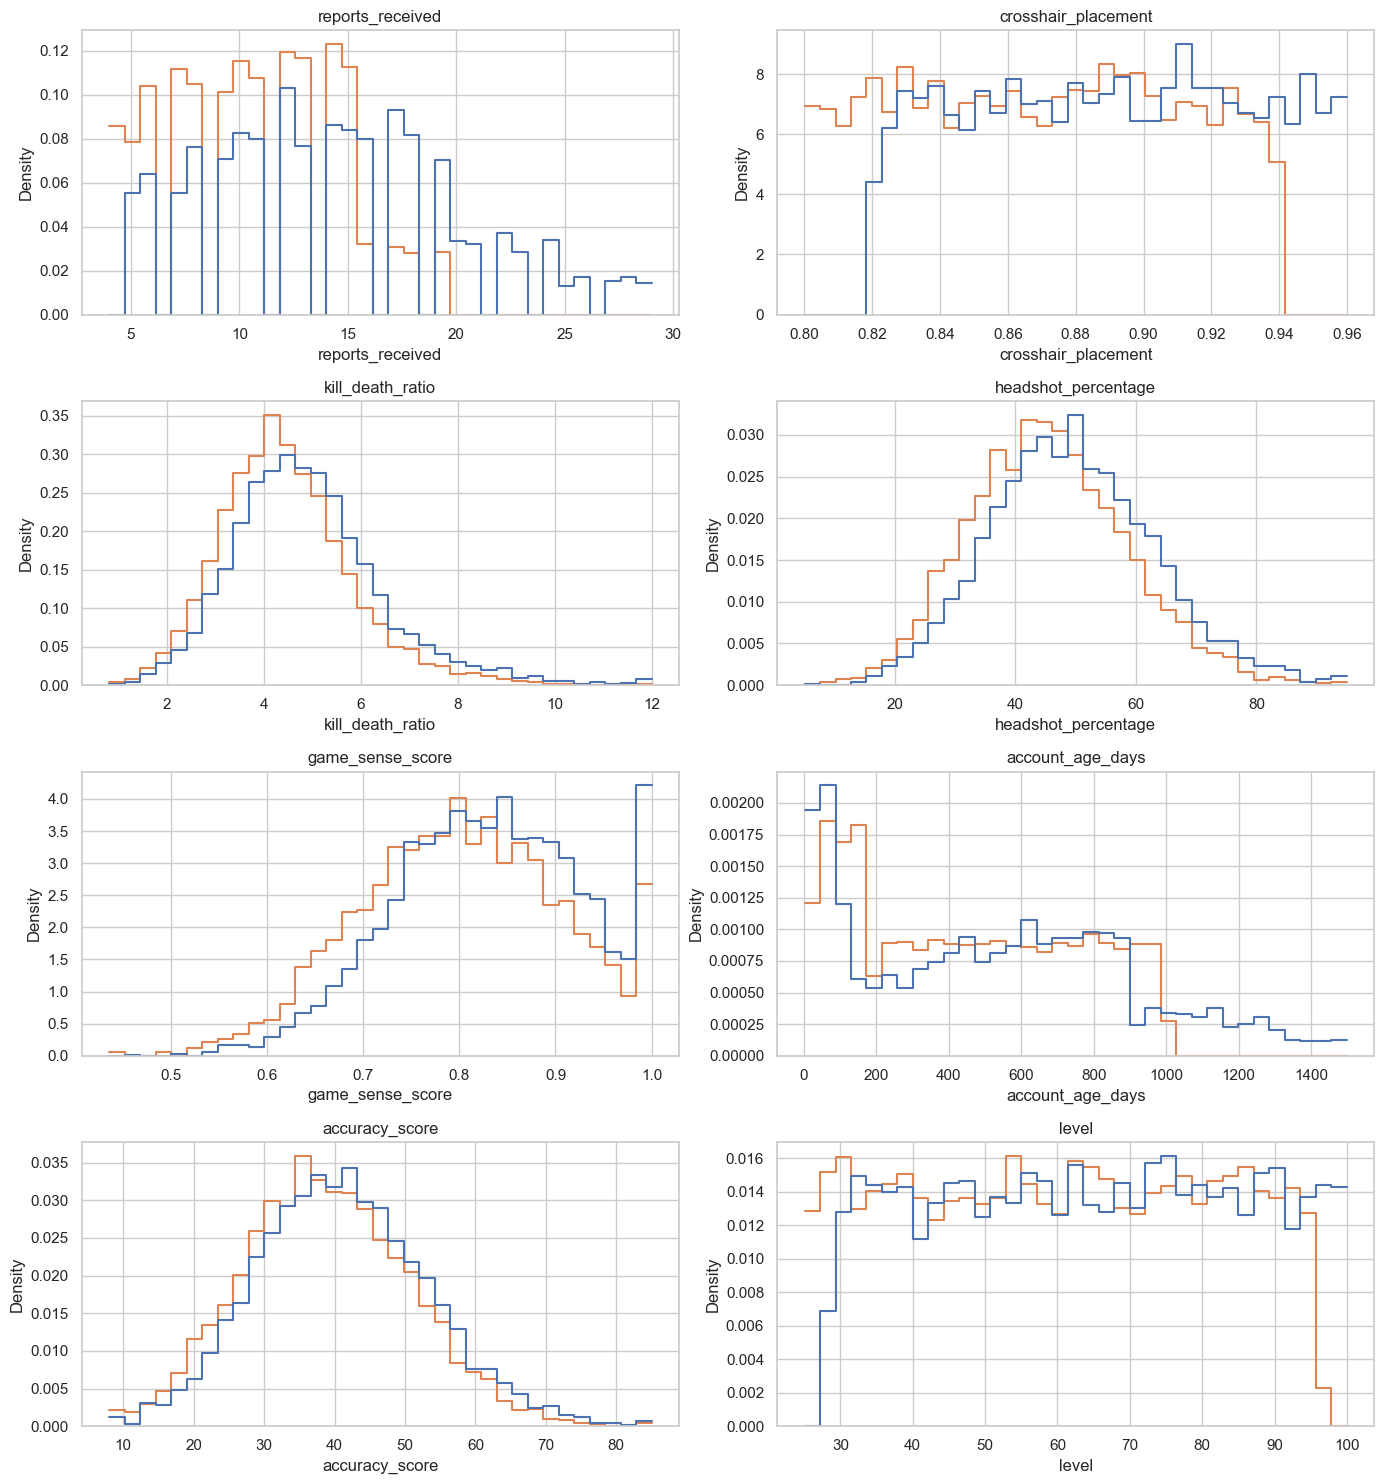

In [11]:
top_features = target_corr.abs().head(8).index.tolist()
plot_data = pd.concat([group.sample(n=min(len(group), 5000), random_state=SEED)
                       for _, group in train_clean.groupby(TARGET)])
fig, axes = plt.subplots(4, 2, figsize=(14, 15))
for column, ax in zip(top_features, axes.flat):
    sns.histplot(data=plot_data, x=column, hue=TARGET, hue_order=[0, 1],
                 stat="density", common_norm=False, bins=35, element="step",
                 fill=False, ax=ax, legend=False)
    ax.set_title(column)
plt.tight_layout()
plt.show()

In [12]:
# ID is kept for submission matching, but it is not a model feature.
print("Model feature columns:", len(feature_cols))
print("Clean labeled rows:", len(train_clean))
print("Unlabeled train rows excluded:", len(train_raw) - len(train_clean))
print("Test rows retained:", len(test_clean))
print("Feature NaNs kept for model-stage preprocessing:", train_clean[feature_cols].isna().sum().sum())

Model feature columns: 31
Clean labeled rows: 90816
Unlabeled train rows excluded: 13184
Test rows retained: 25889
Feature NaNs kept for model-stage preprocessing: 336958


# Save dataset

In [13]:
from src.pipeline.save_data import save_data

assert len(feature_cols) == 31
assert train_clean.columns.tolist() == test_clean.columns.tolist() + [TARGET]
assert train_clean[TARGET].notna().all()
assert test_clean.equals(test_raw)

original_info = save_data(
    task=1,
    name="eda_original_v1",
    train=train_clean,
    test=test_clean,
    card={
        "source": "task1/data/raw/train.csv and test.csv",
        "preparation": "Excluded 13,184 unlabeled train rows; cast is_cheater to int8; kept all 31 raw features and player_id; no imputation or fitted transforms.",
    },
    format="parquet",
)
print(original_info["splits"]["train"]["path"])
print(original_info["splits"]["test"]["path"])

task1/data/eda/eda_original_v1-train.parquet
task1/data/eda/eda_original_v1-test.parquet
